# The rest of the paper's figures

`chq_vs_ch_demo.ipynb` covers the coupled-vs-uncoupled morphology/energy comparison. This notebook covers the remaining figures from the paper (short draft):

1. **Discrete energy identity $(\star)$ residual** — live (dense solve, tiny grids, a few seconds).
2. **MMS temporal convergence** — live ($N=40$, under a minute).
3. **Agreement with an independent nonlinear Newton–BDF2 solver** — live ($N=19$, a few seconds).
4. **Headline demonstration: energy and mass conservation at three $\Delta t$** — from saved data. These three $N=128$, $T=10$ runs ($\Delta t=10^{-2},10^{-3},10^{-4}$) took 14,303 s, 42,011 s and 69,674 s of wall-clock time respectively when the paper's figures were generated — about **34 hours combined** — so this part loads the saved results.
5. **$\phi$ morphology at the larger double-well prefactor ($W=5$, appendix)** — from saved data. This $N=64$, $T=2$ run took 513 s (≈8.5 min); still re-runnable, but too slow for a quick demo, so it also loads saved data.

In [1]:
%matplotlib inline
import scienceplots 
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "chq_sav")))

import numpy as np
import matplotlib.pyplot as plt
plt.style.use(['science'])
import chq_sav as sav
import chq_nonlinear as nl
from chqpy_coef import chqpy_coefficients
from mms import make_mms

data_dir = os.path.join("..", "data")

plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"""
        \usepackage{amsmath}
        \usepackage{amssymb}
        \usepackage{type1cm}
    """,
    "font.size": 18,
    "axes.titlesize": 16,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
})

## 1 — Discrete energy identity $(\star)$ residual (live)

The discrete energy identity $(\star)$ (Theorem on the modified energy) is an *algebraic* identity of the scheme's own equations — it should hold at every step, up to the linear solver's tolerance (here: machine round-off, since this check uses the dense direct solve). We check a well-resolved smooth-IC case and a deliberately under-resolved noisy-IC case (where a safety clamp becomes active) and confirm the residual stays at round-off in both.

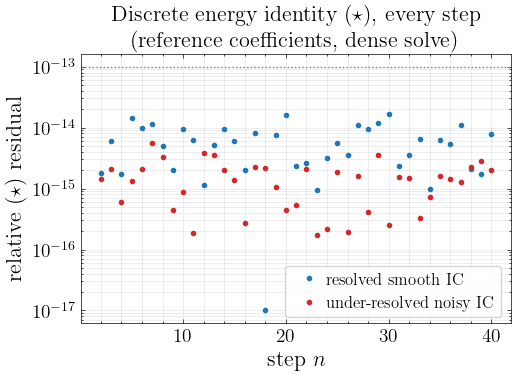

In [2]:
coef = chqpy_coefficients(gamma=1e-3, W=3.0)

g_res = sav.SpectralGrid2D(32, 32, 1.0, 1.0)
kx, ky = 2 * np.pi / g_res.Lx, 2 * np.pi / g_res.Ly
phi0_res = 0.4 + 0.08 * np.cos(kx * g_res.X) * np.cos(ky * g_res.Y)
q0_res = 0.01 * np.sin(kx * g_res.X) * np.sin(ky * g_res.Y)

rng = np.random.default_rng(1)
g_ur = sav.SpectralGrid2D(9, 9, 1.0, 1.0)
phi0_ur = 0.4 + 0.55 * rng.uniform(-1.0, 1.0, size=g_ur.shape)
q0_ur = 0.01 * rng.uniform(-1.0, 1.0, size=g_ur.shape)

cases = [
    ("resolved smooth IC", g_res, phi0_res, q0_res, "#1f77b4"),
    ("under-resolved noisy IC", g_ur, phi0_ur, q0_ur, "#d62728"),
]

fig, ax = plt.subplots(figsize=(5.6, 4.2))
for label, g, phi0, q0, color in cases:
    res = sav.run(coef, phi0, q0, T=0.02, dt=0.0005, grid=g, backend="dense",
                  check_star=False, diagnostics=True)
    steps = [r["step"] for r in res.log]
    star = [max(r["star_rel"], 1e-17) for r in res.log]
    clampf = max(r["clamp_frac"] for r in res.log)
    # ax.semilogy(steps, star, ".", ms=4, color=color,
                # label=f"{label}\n(max clamp frac {clampf:.2f})")
    ax.semilogy(steps, star, ".", ms=6, color=color,
                label=f"{label}")
ax.axhline(1e-13, color="grey", ls=":", lw=1)
ax.set_xlabel("step $n$")
ax.set_ylabel(r"relative $(\star)$ residual")
ax.set_title("Discrete energy identity $(\\star)$, every step\n(reference coefficients, dense solve)")
ax.legend(loc=(0.475,0.02),frameon=True,handletextpad=0.05,fontsize=12)
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig("./Figs/fig_chqpy_W3_star_residual.pdf")
plt.show()

## 2 — MMS temporal convergence (live)

A smooth manufactured solution with matching forcing isolates the scheme's time-discretisation order from any spatial under-resolution. Expect slope 2 (BDF2) for both startup methods.

In [3]:
def run_mms_case(N, dt, T, startup, gmres_tol=1e-11):
    g = sav.SpectralGrid2D(N, N, 1.0, 1.0)
    coef = chqpy_coefficients(gamma=0.30, W=3.0)
    phi_ex, q_ex, forcing = make_mms(g, coef)
    res = sav.run(coef, phi_ex(0.0), q_ex(0.0), T=T, dt=dt, grid=g, backend="gmres",
                  gmres_tol=gmres_tol, startup_method=startup, forcing=forcing)
    return float(np.max(np.abs(res.final[0] - phi_ex(T))))


N, T = 40, 0.04
dts = np.array([1.6e-3, 8e-4, 4e-4, 2e-4, 1e-4])
errs = {}
for startup in ("be", "richardson"):
    e = [run_mms_case(N, dt, T, startup) for dt in dts]
    errs[startup] = np.array(e)
    p = np.log2(np.array(e[:-1]) / np.array(e[1:]))
    print(f"{startup}: p_t = {[f'{x:.2f}' for x in p]}")



be: p_t = ['2.01', '2.00', '2.00', '2.00']


richardson: p_t = ['1.68', '1.81', '1.90', '1.95']


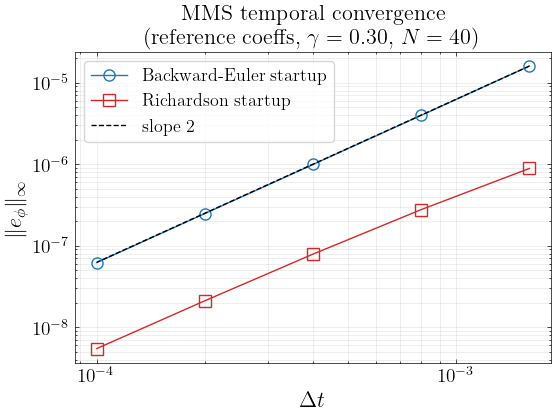

In [4]:
fig, ax = plt.subplots(figsize=(6.0, 4.6))
colors = {"be": "#1f77b4", "richardson": "#d62728"}
labels = {"be": "Backward-Euler startup", "richardson": "Richardson startup"}
markers = {"be": "o", "richardson": "s"}
for startup in ("be", "richardson"):
    ax.loglog(dts, errs[startup], color=colors[startup],marker=markers[startup], label=labels[startup],mfc="None",mew=1,ms=8)
ref_dt = np.array([dts[0], dts[-1]])
ref_e = errs["be"][0] * (ref_dt / dts[0]) ** 2
ax.loglog(ref_dt, ref_e, "k--", lw=1, label="slope 2")
ax.set_xlabel(r"$\Delta t$")
ax.set_ylabel(r"$\|e_\phi\|_\infty$")
ax.set_title(f"MMS temporal convergence\n(reference coeffs, $\\gamma=0.30$, $N={N}$)")
ax.legend(fontsize=13,frameon=True,loc="upper left")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig("./Figs/fig_chqpy_W3_convergence.pdf")
plt.show()

## 3 — Agreement with an independent nonlinear Newton–BDF2 solver (live)

`chq_nonlinear.py` solves the same CHQ model with a completely different scheme (BDF2 + Newton on $f'(\phi)$, no SAV reformulation). If the linear SAV scheme is faithful to the model, the two should agree to $O(\Delta t^2)$.

orders: ['2.04', '2.02', '2.00', '2.01']


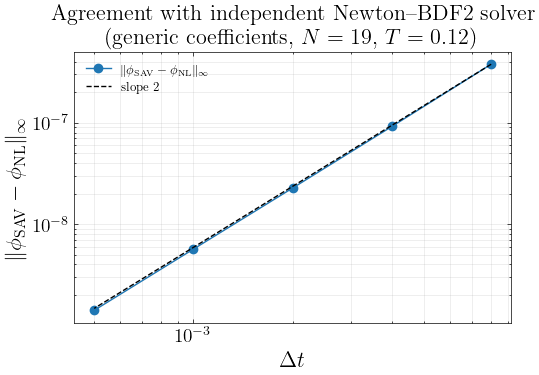

In [5]:
g = sav.SpectralGrid2D(19, 19, 2 * np.pi, 2 * np.pi)
coef = sav.generic()
phi0 = 0.5 + 0.12 * np.cos(g.X) * np.cos(g.Y)
q0 = 0.01 * np.sin(g.X) * np.sin(2 * g.Y)
T = 0.12
dts = np.array([8e-3, 4e-3, 2e-3, 1e-3, 5e-4])

diffs = []
for dt in dts:
    rS = sav.run(coef, phi0, q0, T=T, dt=dt, grid=g, backend="gmres", check_star=False)
    sN, logN = nl.nl_run(coef, phi0, q0, T=T, dt=dt, grid=g, backend="gmres")
    diffs.append(float(np.max(np.abs(rS.final[0] - sN[0]))))
diffs = np.array(diffs)
p = [np.log2(diffs[i] / diffs[i + 1]) for i in range(len(diffs) - 1)]
print("orders:", [f"{x:.2f}" for x in p])

fig, ax = plt.subplots(figsize=(5.6, 4.2))
ax.loglog(dts, diffs, "o-", color="#1f77b4",
          label=r"$\|\phi_{\mathrm{SAV}}-\phi_{\mathrm{NL}}\|_\infty$")
ref_dt = np.array([dts[0], dts[-1]])
ref_e = diffs[0] * (ref_dt / dts[0]) ** 2
ax.loglog(ref_dt, ref_e, "k--", lw=1, label="slope 2")
ax.set_xlabel(r"$\Delta t$")
ax.set_ylabel(r"$\|\phi_{\mathrm{SAV}}-\phi_{\mathrm{NL}}\|_\infty$")
ax.set_title("Agreement with independent Newton–BDF2 solver\n(generic coefficients, $N=19$, $T=0.12$)")
ax.legend(fontsize=9)
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

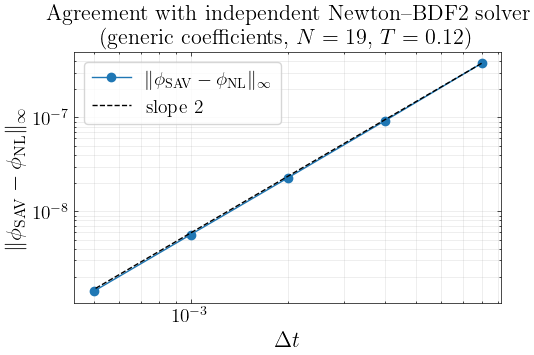

In [6]:
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.loglog(dts, diffs, "o-", color="#1f77b4",
          label=r"$\|\phi_{\mathrm{SAV}}-\phi_{\mathrm{NL}}\|_\infty$")
ref_dt = np.array([dts[0], dts[-1]])
ref_e = diffs[0] * (ref_dt / dts[0]) ** 2
ax.loglog(ref_dt, ref_e, "k--", lw=1, label="slope 2")
ax.set_xlabel(r"$\Delta t$")
ax.set_ylabel(r"$\|\phi_{\mathrm{SAV}}-\phi_{\mathrm{NL}}\|_\infty$")
ax.set_title("Agreement with independent Newton–BDF2 solver\n(generic coefficients, $N=19$, $T=0.12$)")
ax.legend(fontsize=14,frameon=True)
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig("./Figs/fig_indep_convergence.pdf")
plt.show()

## 4 — Headline demonstration: energy and mass at three $\Delta t$ (from saved data)

$N=128$, $T=10$, reference coefficients, $\Delta t \in \{10^{-2},10^{-3},10^{-4}\}$ (1,000 / 10,000 / 100,000 BDF2 steps). GMRES was solved to a relative tolerance of $10^{-10}$ at every step. The mass-conservation identity is exact only if the linear system is solved exactly, so the drift floor visible at the finest $\Delta t$ tracks the GMRES tolerance, not round-off.

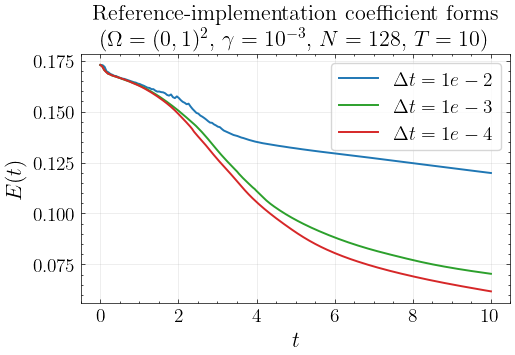

In [7]:
DTS = [("1e-2", "dt0.01", "#1f77b4"),
       ("1e-3", "dt0.001", "#2ca02c"),
       ("1e-4", "dt0.0001", "#d62728")]

fig, ax = plt.subplots(figsize=(5.5, 4))
for label, tag, color in DTS:
    d = np.load(os.path.join(data_dir, f"headline_energy_{tag}.npz"))
    ax.plot(d["t"], d["E"], "-", lw=1.4, color=color, label=rf"$\Delta t={label}$")
ax.set_xlabel(r"$t$")
ax.set_ylabel(r" $E(t) $")
ax.set_title("Reference-implementation coefficient forms\n($\\Omega=(0,1)^2$, $\\gamma=10^{-3}$, $N=128$, $T=10$)")
ax.legend(fontsize=14,frameon=True)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("./Figs/fig_chqpy_W3_energy_dt.pdf")
plt.show()

dt=1e-2: wall-clock of the original run = 14303 s
dt=1e-3: wall-clock of the original run = 42011 s
dt=1e-4: wall-clock of the original run = 69674 s


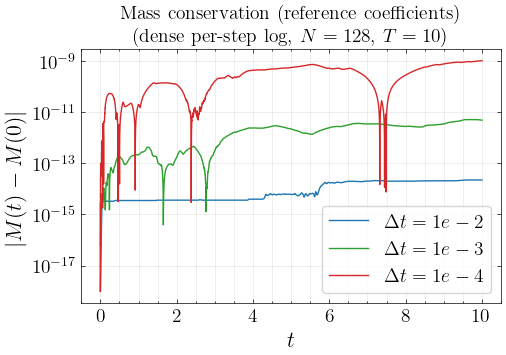

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 4))
for label, tag, color in DTS:
    d = np.load(os.path.join(data_dir, f"headline_mass_{tag}.npz"))
    t, mass, M0 = d["t"], d["mass"], float(d["M0"])
    err = np.maximum(np.abs(mass - M0), 1e-18)
    ax.semilogy(t, err, "-", lw=1.0, color=color, label=rf"$\Delta t={label}$")
    print(f"dt={label}: wall-clock of the original run = {float(d['wall']):.0f} s")
ax.set_xlabel(r"$t$")
ax.set_ylabel(r"$|M(t)-M(0)|$")
ax.set_title("Mass conservation (reference coefficients)\n(dense per-step log, $N=128$, $T=10$)", fontsize=14)
ax.legend(fontsize=14,frameon=True)
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.savefig("./Figs/fig_chqpy_W3_mass_dt.pdf")
plt.show()

## 5 — SAV auxiliary variable drift at three $\Delta t$ (from saved data)

The SAV trick replaces the nonlinear term $f'(\phi)$ with $r\,G(\phi)$, where the scalar $r$ is evolved by its own (linear) update rather than being reset to its exact value $r_\mathrm{true}=\sqrt{\int f(\phi)+C_0}$ every step. The scheme's correctness only requires $r$ to *track* $r_\mathrm{true}$, not equal it exactly; this is the drift $|r-r_\mathrm{true}|$ plotted below, logged at every step of the same three headline runs ($N=128$, $T=10$) used for the energy and mass plots above, at reference coefficients. It shrinks sharply as $\Delta t\to0$, consistent with $r$ being a first-order-consistent (in the scheme's own sense) proxy for $r_\mathrm{true}$.

dt=1e-2: max |r - r_true| = 7.262e-01
dt=1e-3: max |r - r_true| = 2.848e-01
dt=1e-4: max |r - r_true| = 3.418e-05


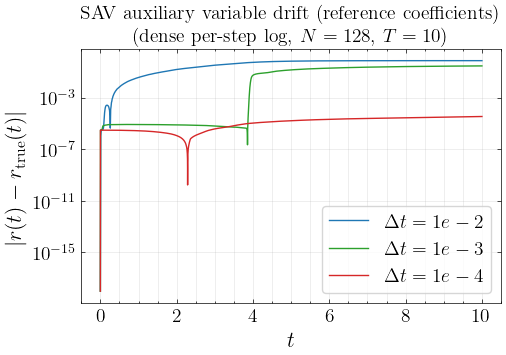

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 4))
for label, tag, color in DTS:
    d = np.load(os.path.join(data_dir, f"headline_rdrift_{tag}.npz"))
    t, rdrift = d["t"], np.maximum(d["r_drift"], 1e-18)
    ax.semilogy(t, rdrift, "-", lw=1.0, color=color, label=rf"$\Delta t={label}$")
    print(f"dt={label}: max |r - r_true| = {float(d['r_drift'].max()):.3e}")
ax.set_xlabel(r"$t$")
ax.set_ylabel(r"$|r(t)-r_\mathrm{true}(t)|$")
ax.set_title("SAV auxiliary variable drift (reference coefficients)\n(dense per-step log, $N=128$, $T=10$)", fontsize=14)
ax.legend(fontsize=14,frameon=True)
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.savefig("./Figs/fig_chqpy_W3_rdrift_dt.pdf")
plt.show()